# Assignment 3 — Module 3: Evolutionary and Swarm Optimization


## Practical 3: Selection Methods in Genetic Algorithms

### Aim
To implement basic selection methods for selecting suitable individuals from a population using Python.

### Theory
**Selection** chooses which individuals become parents, with better individuals more likely to be chosen. Strong selection pressure converges fast but risks losing diversity.

- **Roulette-wheel selection:** probability proportional to fitness, $P_i = \frac{f_i}{\sum_j f_j}$.
- **Tournament selection:** pick $k$ individuals at random and keep the best.
- **Rank selection:** probability depends on the rank of the individual, not its raw fitness value, which avoids domination by one very fit individual.

### Implementing the three selection operators

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)

def roulette_wheel_selection(fits, n):
    probs = fits / fits.sum()
    return rng.choice(len(fits), size=n, p=probs)

def tournament_selection(fits, n, k=3):
    chosen = []
    for _ in range(n):
        contenders = rng.choice(len(fits), size=k, replace=False)
        chosen.append(contenders[np.argmax(fits[contenders])])
    return np.array(chosen)

def rank_selection(fits, n):
    order = np.argsort(fits)                   # ascending: worst ... best
    ranks = np.empty_like(order)
    ranks[order] = np.arange(1, len(fits) + 1) # rank 1 = worst, rank N = best
    probs = ranks / ranks.sum()
    return rng.choice(len(fits), size=n, p=probs)

### Comparing selection pressure

In [2]:
# Fixed population of fitness values (higher = better)
fits = np.array([0.10, 0.25, 0.40, 0.55, 0.70, 0.90, 0.95, 0.20])
best_idx = np.argmax(fits)
N_DRAWS = 5000

methods = {
    'Roulette wheel': roulette_wheel_selection(fits, N_DRAWS),
    'Tournament (k=3)': tournament_selection(fits, N_DRAWS, k=3),
    'Rank': rank_selection(fits, N_DRAWS),
}

for name, sel in methods.items():
    freq = np.mean(sel == best_idx)
    print(f"{name:18s}: best individual selected {freq*100:5.2f}% of the time")

Roulette wheel    : best individual selected 23.54% of the time
Tournament (k=3)  : best individual selected 37.28% of the time
Rank              : best individual selected 22.54% of the time


### Visualizing selection frequencies

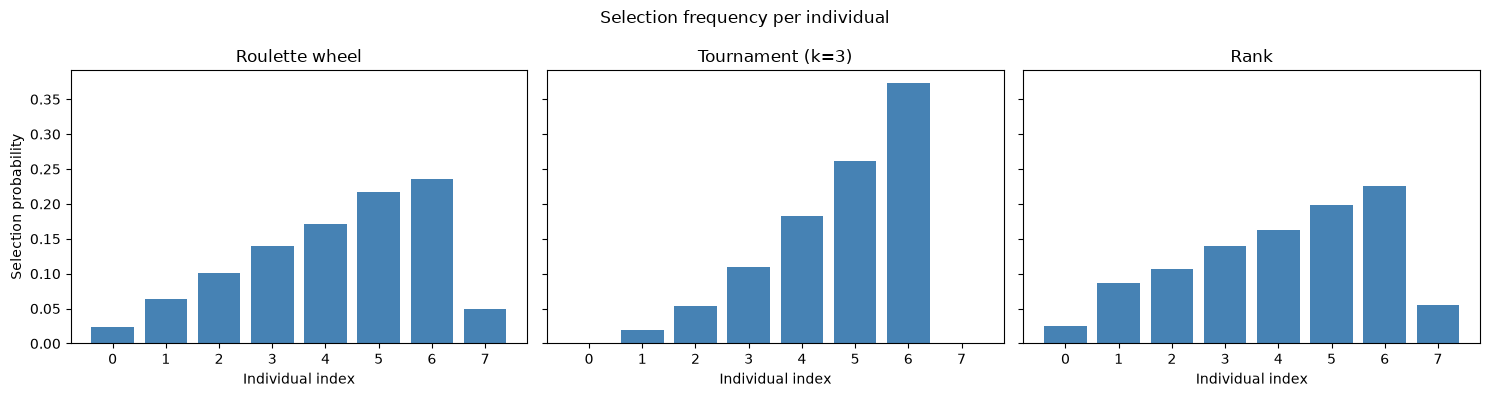

Fitness values by index: [0.1  0.25 0.4  0.55 0.7  0.9  0.95 0.2 ]


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (name, sel) in zip(ax, methods.items()):
    counts = np.bincount(sel, minlength=len(fits))
    a.bar(range(len(fits)), counts / N_DRAWS, color='steelblue')
    a.set_title(name)
    a.set_xlabel('Individual index')
ax[0].set_ylabel('Selection probability')
plt.suptitle('Selection frequency per individual')
plt.tight_layout(); plt.show()
print("Fitness values by index:", fits)

### Observation
- Roulette-wheel selection gives the fittest individual a probability roughly proportional to its share of total fitness.
- Tournament selection gives a stronger bias toward the best individual as $k$ grows, because the best individual wins every tournament it enters.
- Rank selection reduces the dominance of one very high fitness value compared with roulette-wheel selection.

### Conclusion
Implemented roulette-wheel, tournament and rank selection, and compared their selection pressure by measuring how often the best individual is chosen.